# 03. Пилот стандарта сварки WS-2: работает ли он и стоит ли тиражировать

**Контекст.** С 01.09.2025 служба главного технолога внедрила новый стандарт сварки WS-2 (изменённые режимы, дополнительная зачистка и пооперационный контроль) на трёх из шести сварочных участков. Остальные три работают по-старому. Через год нужно решение: **тиражировать стандарт на все участки или нет.**

**Почему нельзя просто сравнить «до и после».** За тот же год сварка улучшалась на всех участках (обновление оснастки, обучение) - сравнение «до/после» на пилотных участках припишет стандарту и этот общий тренд. Сравнение «пилот vs контроль» после старта тоже некорректно: пилотные участки исходно отличались (сварка рам грузовиков и спецтехники сложнее). Поэтому используем **разность разностей (difference-in-differences, DiD)**: изменение на пилоте минус изменение на контроле.

| Группа | Участки |
|---|---|
| Пилот | ЦЛА сварка кузовов №1, ЦГА сварка рам, ЦСТ сварка |
| Контроль | ЦЛА сварка кузовов №2, ЦГА сварка кузовов автобусов, ЦМТ сварка рам |

Выбор участков в пилот не был случайным - это ограничение, с которым работаем через проверку параллельности трендов и плацебо-тесты.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.formula.api as smf
from helpers import q, save, pct, BLUE, ORANGE, GRAY, GRAY_LIGHT, INK_2

panel = q("select * from marts.mart_welding_pilot order by month_start, section_id")
panel["pilot"] = (panel["ws2_group"] == "pilot").astype(int)
panel["post"] = panel["is_post_period"].astype(int)
panel.groupby(["ws2_group", "post"])[["operations", "defect_operations"]].sum().assign(
    defect_rate=lambda d: d["defect_operations"] / d["operations"])

operations  defect_operations  defect_rate
ws2_group post                                            
control   0           5849                211     0.036075
          1           7320                243     0.033197
pilot     0           4024                200     0.049702
          1           5028                149     0.029634

## 1. Параллельность трендов до пилота
DiD корректен, если без вмешательства группы менялись бы одинаково. Проверяем по 11 месяцам до старта.

Различие трендов до пилота (pilot:t): +0.00109 в месяц, p = 0.30 -> значимого расхождения трендов нет


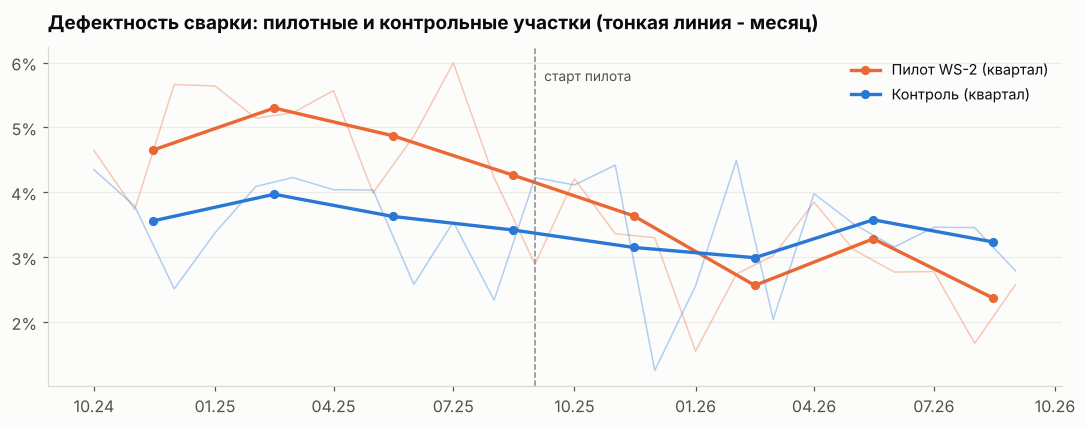

In [2]:
g = panel.groupby(["month_start", "ws2_group"])[["operations", "defect_operations"]].sum()
g["rate"] = g["defect_operations"] / g["operations"]
gp = g["rate"].unstack()
gq = g.reset_index().assign(qtr=lambda d: d["month_start"].dt.to_period("Q").dt.start_time).groupby(
    ["qtr", "ws2_group"])[["operations", "defect_operations"]].sum()
gq = (gq["defect_operations"] / gq["operations"]).unstack()

fig, ax = plt.subplots(figsize=(10, 4))
for grp, color, name in [("pilot", ORANGE, "Пилот WS-2"), ("control", BLUE, "Контроль")]:
    ax.plot(gp.index, gp[grp], color=color, lw=1, alpha=0.35)
    ax.plot(gq.index + pd.Timedelta(days=45), gq[grp], color=color, lw=2.2, marker="o", ms=5, label=f"{name} (квартал)")
ax.axvline(pd.Timestamp("2025-09-01"), color=GRAY, ls="--", lw=1)
ax.text(pd.Timestamp("2025-09-08"), ax.get_ylim()[1] * 0.95, "старт пилота", fontsize=9, color=INK_2, va="top")
pct(ax, 0)
ax.legend(loc="upper right")
ax.set_title("Дефектность сварки: пилотные и контрольные участки (тонкая линия - месяц)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%y"))
save(fig, "03_ws2_trends")

pre = panel[panel["post"] == 0].copy()
pre["t"] = (pre["month_start"] - pre["month_start"].min()).dt.days / 30.4
trend_test = smf.wls("defect_rate ~ pilot:t + t + C(section_id)", data=pre, weights=pre["operations"]).fit(
    cov_type="cluster", cov_kwds={"groups": pre["section_id"]})
print(f"Различие трендов до пилота (pilot:t): {trend_test.params['pilot:t']:+.5f} в месяц, "
      f"p = {trend_test.pvalues['pilot:t']:.2f} -> значимого расхождения трендов нет")

До старта пилотные участки дефектнее контрольных (разный состав работ), но тренды идут параллельно - статистически значимого различия наклонов нет. После старта пилотная группа отрывается вниз.

## 2. Оценка эффекта
Три оценки - чтобы показать, насколько важен правильный дизайн:

In [3]:
tot = panel.groupby(["pilot", "post"])[["operations", "defect_operations"]].sum()
r = (tot["defect_operations"] / tot["operations"]).unstack()
naive_before_after = r.loc[1, 1] / r.loc[1, 0] - 1
naive_cross = r.loc[1, 1] / r.loc[0, 1] - 1
did_ratio = (r.loc[1, 1] / r.loc[1, 0]) / (r.loc[0, 1] / r.loc[0, 0]) - 1
pd.DataFrame({
    "Оценка": ["«До/после» на пилоте", "«Пилот vs контроль» после старта", "Разность разностей (относит.)"],
    "Эффект": [naive_before_after, naive_cross, did_ratio],
    "Что не так / так": ["включает общий тренд улучшения сварки", "смешано с исходной разницей участков",
                         "убирает и тренд, и исходную разницу"],
}).style.format({"Эффект": "{:+.1%}"})

,Оценка,Эффект,Что не так / так
0,«До/после» на пилоте,-40.4%,включает общий тренд улучшения сварки
1,«Пилот vs контроль» после старта,-10.7%,смешано с исходной разницей участков
2,Разность разностей (относит.),-35.2%,"убирает и тренд, и исходную разницу"


Основная модель - логистическая регрессия на уровне операций с фиксированными эффектами участка и месяца (two-way FE): эффект WS-2 - коэффициент при `pilot × post`. Стандартные ошибки кластеризуем по участкам. Шесть кластеров - мало для асимптотики, поэтому вывод о значимости делаем по **рандомизационному тесту**: перебираем все 20 способов назначить 3 участка из 6 «пилотными» и смотрим, насколько исключительна реальная оценка.

In [4]:
ops = q("""
select o.caused_defect::int as defect, o.section_id, o.month_start::text as month,
       (o.ws2_group = 'pilot')::int as pilot, o.is_ws2_post_period::int as post,
       o.duration_min / o.std_minutes as time_ratio, dm.category_code as category
from marts.fct_operations o join marts.dim_model dm using (model_id)
where o.ws2_group is not null and not o.is_rework
""")
ops["treat"] = ops["pilot"] * ops["post"]
m = smf.logit("defect ~ treat + C(section_id) + C(month) + C(category)", data=ops).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": ops["section_id"]})
or_ = np.exp(m.params["treat"])
lo, hi = np.exp(m.conf_int().loc["treat"])
print(f"WS-2: отношение шансов дефекта {or_:.3f} (95% ДИ {lo:.3f}-{hi:.3f}), "
      f"т.е. снижение шансов на {1 - or_:.0%}")

WS-2: отношение шансов дефекта 0.639 (95% ДИ 0.481-0.848), т.е. снижение шансов на 36%


Реальная оценка (log OR) -0.449; место среди 20 назначений (от самого сильного снижения): 2 -> односторонний рандомизационный p = 0.10
Все оценки: [-0.511 -0.449 -0.43  -0.331 -0.293 -0.232 -0.158 -0.128 -0.072 -0.057
  0.057  0.072  0.128  0.158  0.232  0.293  0.331  0.43   0.449  0.511]


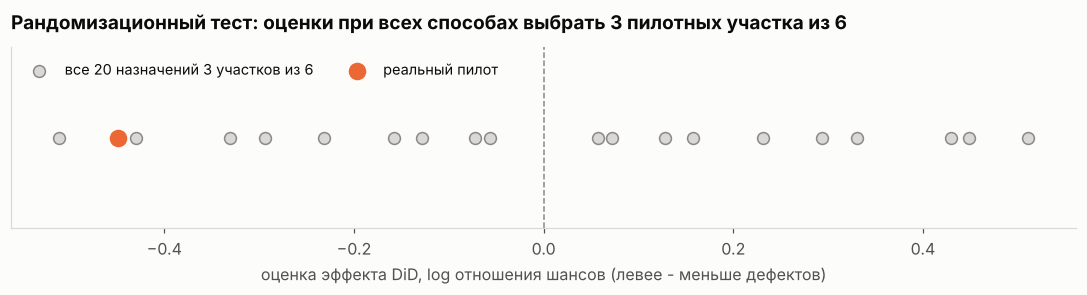

In [5]:
def did_estimate(df, pilots):
    d = df.assign(treat=df["section_id"].isin(pilots).astype(int) * df["post"])
    fit = smf.logit("defect ~ treat + C(section_id) + C(month)", data=d).fit(disp=False)
    return fit.params["treat"]

sections = sorted(ops["section_id"].unique())
real = did_estimate(ops, [1, 8, 13])
placebo = [did_estimate(ops, list(c)) for c in itertools.combinations(sections, 3)]
# Односторонний тест: гипотеза - стандарт СНИЖАЕТ дефектность. Двусторонний здесь неинформативен:
# дополнение к любому назначению (3 других участка) даёт оценку того же модуля с обратным знаком.
p_rand = np.mean(np.array(placebo) <= real + 1e-12)
rank = int(np.sum(np.array(placebo) <= real + 1e-12))
print(f"Реальная оценка (log OR) {real:.3f}; место среди 20 назначений (от самого сильного снижения): {rank}"
      f" -> односторонний рандомизационный p = {p_rand:.2f}")
print("Все оценки:", np.round(sorted(placebo), 3))

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.scatter(placebo, np.zeros(len(placebo)), s=60, color=GRAY_LIGHT, edgecolor=GRAY, zorder=2,
           label="все 20 назначений 3 участков из 6")
ax.scatter([real], [0], s=110, color=ORANGE, zorder=3, label="реальный пилот")
ax.axvline(0, color=GRAY, lw=1, ls="--")
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_xlabel("оценка эффекта DiD, log отношения шансов (левее - меньше дефектов)")
ax.legend(loc="upper left", ncol=2)
ax.set_title("Рандомизационный тест: оценки при всех способах выбрать 3 пилотных участка из 6")
save(fig, "03_ws2_permutation")

Реальный пилот - второе по силе снижение из 20 возможных назначений, односторонний рандомизационный p = 0.10. С шестью участками это почти предел чувствительности теста (минимально возможный p = 0.05), поэтому вывод строим на совокупности: модель с кластеризованными ошибками (ДИ не пересекает 1), параллельные тренды до старта и event study ниже. Честная формулировка: **эффект есть с высокой вероятностью, его величина - около -35% к шансам дефекта, но с широким интервалом** (от -14% до -53%).

## 3. Динамика эффекта по кварталам (event study)
Эффект по каждому кварталу после старта относительно среднего уровня до старта: проверяем, что он устойчив, а не затухает и не держится на одном квартале. (Параллельность до старта проверена выше тестом наклонов.)

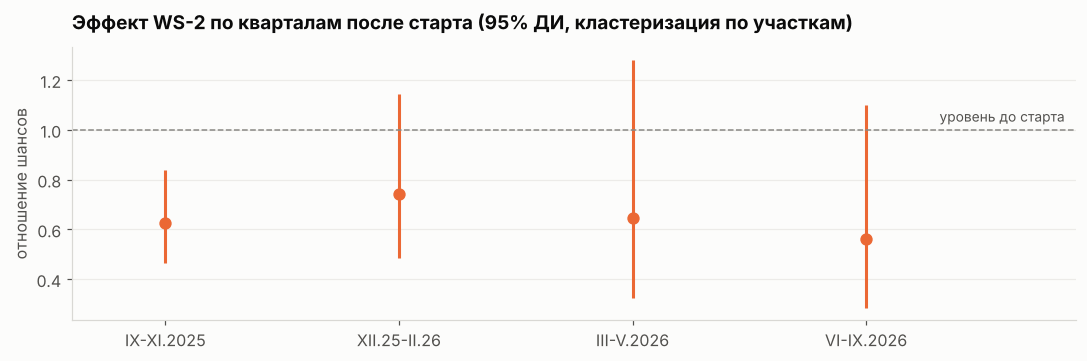

In [6]:
ops["rel_q"] = ((pd.to_datetime(ops["month"]) - pd.Timestamp("2025-09-01")).dt.days // 91).clip(upper=3)
for k in range(0, 4):
    ops[f"q{k}"] = ((ops["rel_q"] == k) & (ops["pilot"] == 1)).astype(int)
terms = " + ".join(f"q{k}" for k in range(0, 4))
es = smf.logit(f"defect ~ {terms} + C(section_id) + C(month)", data=ops).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": ops["section_id"]})
ev = pd.DataFrame([(k, es.params[f"q{k}"], *es.conf_int().loc[f"q{k}"]) for k in range(0, 4)],
                  columns=["k", "b", "lo", "hi"])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.vlines(ev["k"], np.exp(ev["lo"]), np.exp(ev["hi"]), color=ORANGE, lw=2)
ax.scatter(ev["k"], np.exp(ev["b"]), color=ORANGE, s=50, zorder=3)
ax.axhline(1, color=GRAY, lw=1, ls="--")
ax.text(3.85, 1.02, "уровень до старта", va="bottom", ha="right", fontsize=9, color=INK_2)
ax.set_xlim(-0.4, 3.9)
ax.set_xticks(ev["k"], ["IX-XI.2025", "XII.25-II.26", "III-V.2026", "VI-IX.2026"])
ax.set_ylabel("отношение шансов")
ax.set_title("Эффект WS-2 по кварталам после старта (95% ДИ, кластеризация по участкам)")
save(fig, "03_ws2_event_study")

Во всех четырёх кварталах после старта отношение шансов ниже 1 (точечные оценки ~0.6-0.75): стандарт работает с первого квартала и эффект не затухает. Интервалы отдельных кварталов широкие - участков мало, поэтому решение опирается на оценку за весь период.

## 4. Обратная сторона: время операции
WS-2 добавляет зачистку и контроль - значит, операция дольше. Оценим эффект на отношение фактического времени к нормативу той же схемой DiD.

In [7]:
tm = smf.wls("time_ratio ~ treat + C(section_id) + C(month)", data=ops).fit(
    cov_type="cluster", cov_kwds={"groups": ops["section_id"]})
t_eff = tm.params["treat"]
t_lo, t_hi = tm.conf_int().loc["treat"]
base_ratio = ops.loc[(ops["pilot"] == 1) & (ops["post"] == 0), "time_ratio"].mean()
print(f"WS-2: +{t_eff / base_ratio:.1%} к длительности сварочной операции "
      f"(95% ДИ {t_lo / base_ratio:+.1%}..{t_hi / base_ratio:+.1%})")

WS-2: +4.0% к длительности сварочной операции (95% ДИ +3.5%..+4.4%)


## 5. Бизнес-кейс тиражирования на контрольные участки
**Выгода** - предотвращённые дефекты сварки × учтённая стоимость дефекта: фактическая доработка (на линии или после испытаний) + гарантийные выплаты по сварочным дефектам в расчёте на один заводской дефект. Считаем по каждому контрольному участку - стоимость дефекта сильно зависит от изделия.
**Затраты** - дополнительное время сварки (+4%) × полная ставка нормо-часа.

In [8]:
sec = q("""
with ctrl as (
    select section_id, workshop_id, count(*) as ops, sum(caused_defect::int) as defects,
           sum(duration_min) / 60 as weld_hours
    from marts.fct_operations
    where ws2_group = 'control' and not is_rework and work_date between '2025-10-01' and '2026-09-30'
    group by 1, 2
),
d as (select workshop_id, count(*) as plant_defects, avg(rework_cost_rub) as rework_per_defect
      from marts.fct_defects where origin_area = 'WELD' group by 1),
w as (select workshop_id, sum(approved_amount_rub) as warranty from marts.fct_warranty_claims
      where origin_area = 'WELD' group by 1)
select s.section_full_name as section, c.defects, c.weld_hours, d.rework_per_defect,
       coalesce(w.warranty, 0) / d.plant_defects as warranty_per_defect
from ctrl c join d using (workshop_id) left join w using (workshop_id)
join marts.dim_section s using (section_id) order by c.weld_hours desc
""")
rate = float(q("select value from staging.cost_parameters where parameter = 'labor_rate_rub_per_hour'").iloc[0, 0])
effect = 1 - or_
time_up = t_eff / base_ratio
sec["defect_cost"] = sec["rework_per_defect"] + sec["warranty_per_defect"]
sec["avoided"] = sec["defects"] * effect
sec["benefit"] = sec["avoided"] * sec["defect_cost"]
sec["cost"] = sec["weld_hours"] * time_up * rate
sec["net"] = sec["benefit"] - sec["cost"]
sec["breakeven_defect_cost"] = sec["cost"] / sec["avoided"]
sec["breakeven_time_up"] = sec["benefit"] / (sec["weld_hours"] * rate)
fmt = {c: "{:,.0f}" for c in ["defects", "weld_hours", "defect_cost", "avoided", "benefit", "cost", "net",
                              "breakeven_defect_cost"]}
fmt["breakeven_time_up"] = "{:.1%}"
sec[["section", "defects", "weld_hours", "defect_cost", "avoided", "benefit", "cost", "net",
     "breakeven_defect_cost", "breakeven_time_up"]].style.format(fmt)

,section,defects,weld_hours,defect_cost,avoided,benefit,cost,net,breakeven_defect_cost,breakeven_time_up
0,ЦЛА · Участок сварки кузовов №2,129,"6,645","2,668",47,"124,332","382,618","-258,286","8,212",1.3%
1,ЦГА · Участок сварки кузовов автобусов,28,"5,351","9,448",10,"95,549","308,098","-212,549","30,465",1.2%
2,ЦМТ · Участок сварки рам,65,"2,739",973,23,"22,853","157,695","-134,842","6,717",0.6%


Итого по трём контрольным участкам: выгода 243 тыс. ₽/год, затраты на доп. время 848 тыс. ₽/год, чистый эффект -606 тыс. ₽/год
Безубыточность: при текущем эффекте - если стандарт добавляет не более 1.1% времени; при текущих +4.0% - если полная стоимость дефекта сварки не меньше 10,581 ₽ (учтённая сейчас - 3,027 ₽)


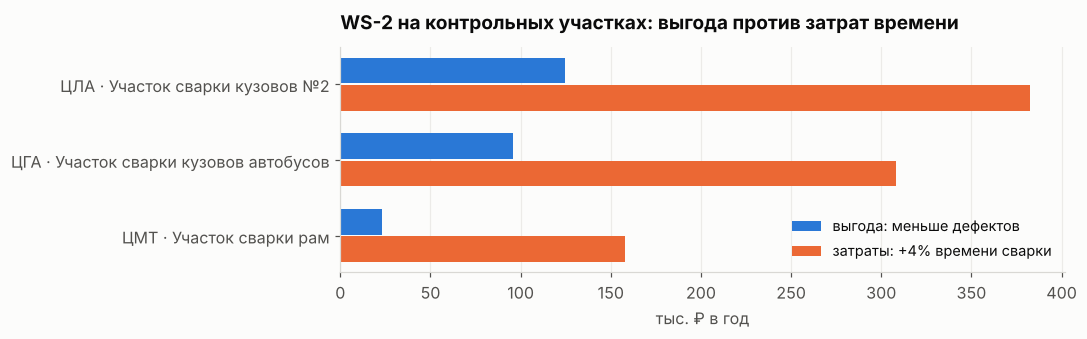

In [9]:
tot = sec[["benefit", "cost", "net"]].sum()
print(f"Итого по трём контрольным участкам: выгода {tot.benefit / 1e3:,.0f} тыс. ₽/год, "
      f"затраты на доп. время {tot.cost / 1e3:,.0f} тыс. ₽/год, чистый эффект {tot.net / 1e3:,.0f} тыс. ₽/год")
be_time = tot.benefit / (sec["weld_hours"].sum() * rate)
be_cost = tot.cost / sec["avoided"].sum()
print(f"Безубыточность: при текущем эффекте - если стандарт добавляет не более {be_time:.1%} времени; "
      f"при текущих +{time_up:.1%} - если полная стоимость дефекта сварки не меньше {be_cost:,.0f} ₽ "
      f"(учтённая сейчас - {np.average(sec['defect_cost'], weights=sec['avoided']):,.0f} ₽)")

fig, ax = plt.subplots(figsize=(10, 3.2))
yy = np.arange(len(sec))[::-1]
ax.barh(yy + 0.18, sec["benefit"] / 1e3, height=0.34, color=BLUE, label="выгода: меньше дефектов")
ax.barh(yy - 0.18, sec["cost"] / 1e3, height=0.34, color=ORANGE, label="затраты: +4% времени сварки")
ax.set_yticks(yy, sec["section"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#ecebe8")
ax.set_xlabel("тыс. ₽ в год")
ax.legend(loc="lower right")
ax.set_title("WS-2 на контрольных участках: выгода против затрат времени")
save(fig, "03_ws2_business_case")

### Вывод и рекомендация
* Стандарт WS-2 **действительно снижает дефектность сварки - примерно на треть** (DiD с фиксированными эффектами, устойчиво в event study). Наивное «до/после» завысило бы эффект почти вдвое за счёт общего тренда улучшения сварки.
* Цена - **+4% ко времени сварочной операции**, и при учтённой стоимости дефекта она **дороже выгоды на всех трёх контрольных участках**: сварочный дефект на заводе в основном ловится и дёшево исправляется (доработка - единицы тысяч рублей), а гарантийные случаи по сварке редки.
* **Рекомендация: не тиражировать WS-2 в текущем виде**, а:
  1. разложить стандарт на элементы и выяснить у технологов, что даёт эффект (режимы сварки бесплатны по времени, сплошная зачистка и контроль - нет); безубыточный вариант должен укладываться в порог по времени из расчёта выше;
  2. уточнить полную стоимость сварочного дефекта: в расчёт не вошли простои линии при возврате изделия с испытаний, задержка отгрузки, риск лома - если она выше порога безубыточности, решение меняется;
  3. для сварки кузовов автобусов (ЦГА) отдельно проверить такт: +4% к операции 600 мин - это ~25 минут на машину на узком месте.
* Это пример, когда **статистически значимый эффект не равен экономически оправданному решению** - и аналитика должна показывать обе стороны.

**Валидация метода.** Данные синтетические, истинный эффект известен: генератор закладывал -35% к вероятности дефекта и +4% ко времени (`data/generated/ground_truth.json`). DiD восстановил оба параметра, наивные методы - нет. Это и есть аргумент за дизайн исследования.